# 2023年Java大厂面试｜04：Spring、Spring MVC、Spring Boot与MyBatis

> 学习目标：能解释Bean如何创建与被代理，识别事务和循环依赖的边界，讲清一次HTTP请求与一次Mapper查询的执行过程，并判断自动配置、延迟加载和缓存何时生效。

**主要依据：** `5.2023版Java面试教程/04-框架篇/PPT/04-框架篇.pptx`，53页。已读取全部文字、组合形状、表格与备注，查看20张去重嵌入图片的总览，并单独检查关键问答、循环依赖图、自动配置代码和MyBatis调试截图。第53页为空白。

课件第36页明确出现`spring-boot-autoconfigure:2.3.9.RELEASE`，自动配置入口按这个时代讲解；笔记补充较新Spring/Boot/MyBatis版本的区别，不能将旧源码片段当作所有版本的固定实现。

视频目录有12节，仅核对文件标题，未观看或转写。配套代码目录有`mybatis-demo.zip`、`spring-demo.zip`、`ssm-demo.zip`；下载尝试未获得代码包，网盘提示“验证码已过期”，因此代码包正文未读取、项目未运行。`在线讲义文稿.txt`只有一行飞书URL；已访问专题目录，点击“SSM框架”后未显示正文，未将在线正文作为已读来源。

“课件要点”表示原资料内容；“补充说明”“修正”表示整理者补充的机制、示例改写或适用条件。以下代码为学习片段，省略部分导入与业务实现，均未编译或执行。未连接数据库、启动课程项目、进行并发测试或修改用户应用配置。

### 目录

- 1～3：框架关系、Bean作用域与单例线程安全
- 4～6：AOP、操作日志、代理与内部调用
- 7～9：事务实现、传播行为与事务失效排查
- 10～13：Bean生命周期、初始化与销毁、三级缓存、循环依赖边界
- 14～19：Spring MVC流程、消息转换、常见注解、Boot自动配置
- 20～26：MyBatis执行、参数映射、延迟加载、一二级缓存与一致性
- 27～30：面试自测、练习方案、课件修正、来源与覆盖范围

课件中的“我们项目”与截图是课程案例，不能直接写成自己的开发经历。


## 1. 四个框架如何协作

**课件第2页：** Spring部分包括Bean线程安全、AOP、事务、生命周期与循环依赖；Spring MVC讲请求流程；Spring Boot讲自动配置；MyBatis讲SQL执行、延迟加载和缓存。

| 框架 | 主要职责 | 常见追问 |
|---|---|---|
| Spring Framework | IoC/DI、Bean管理、AOP、事务抽象等 | Bean怎么创建，代理是否生效，生命周期与依赖关系 |
| Spring MVC | 基于Servlet的Web请求处理 | 路由、参数绑定、消息转换、异常和视图 |
| Spring Boot | 启动、自动配置、依赖与约定支持 | 哪个配置类生效，条件如何判断，版本入口差异 |
| MyBatis | SQL映射与JDBC访问 | Mapper代理、参数/结果处理、缓存与关联加载 |

**补充完整链路：**

~~~text
HTTP请求 → Servlet过滤器链 → DispatcherServlet
         → HandlerMapping / HandlerAdapter
         → Controller → Service代理 → 事务拦截
         → Mapper代理 → MyBatis执行器 → JDBC → 数据库
         ← 结果映射 ← 业务结果 ← 事务提交或回滚
         ← HttpMessageConverter或视图渲染 ← HTTP响应
~~~

这是典型Servlet应用示意，组件是否存在与项目配置有关。Spring WebFlux有另一套响应式处理模型；本篇不能直接把DispatcherServlet流程套到WebFlux。

**面试准备：** 选自己做过的一次请求，讲清请求参数进入哪个方法，Service事务怎么拦截，Mapper怎么找到SQL，返回值怎样变成JSON。未实践过的组件，说明是课程学习范围。


## 2. Bean作用域与singleton的含义

**课件第3～5页：** 默认作用域是singleton；prototype每次请求容器创建时可以获得新实例。

~~~java
// 学习片段，未编译/执行
@Service
@Scope("singleton")
public class UserServiceImpl implements UserService {
    // 业务方法
}
~~~

| 作用域 | 含义 | 使用时注意 |
|---|---|---|
| singleton | 每个容器中，每个Bean定义通常只有一个实例 | 不等于整个JVM只能有一个同类对象 |
| prototype | 每次向容器获取该定义时创建新实例 | 不等于每调用一个业务方法就重新创建 |
| request（补充） | Web环境中一次请求范围 | 注入长生命周期对象时需相应代理/提供者等 |
| session（补充） | Web环境中一个HTTP会话范围 | 会话也可能并发访问，不天然线程安全 |

同一个类可对应多个Bean定义；多个ApplicationContext也可能各有实例。“单例”约束的是容器管理方式，不能证明实例中方法线程安全。

**prototype注入陷阱：** 单例Service创建时注入一个prototype对象，默认只在注入时获取一次，此后Service可能一直引用它。若确实每次需要新对象，可用`ObjectProvider.getObject()`等方式按需获取，或采用匹配生命周期的作用域代理；仍需分析对象是否共享。

**补充示意：**

~~~java
@Service
public class TaskService {
    private final ObjectProvider<TaskState> states;
    public TaskService(ObjectProvider<TaskState> states) {
        this.states = states;
    }
    public void execute() {
        TaskState state = states.getObject(); // TaskState需定义为prototype等
        // 在本次工作中使用state；不要再保存到共享字段
    }
}
~~~

作用域由业务生命周期决定。把singleton改为prototype会改变创建、资源管理和共享关系，不能作为所有并发问题的统一修复。


## 3. 单例Bean是否线程安全

**课件第4页：** Controller中保存`private int count`，每次请求执行`count++`。多个请求可能同时访问同一实例，出现共享状态竞争。

~~~java
@RestController
public class CounterController {
    private int count;
    @GetMapping("/count")
    public int count() {
        return ++count; // 教学反例：读、加、写不是原子复合操作
    }
}
~~~

**准确回答：** Spring默认单例不自动保证业务线程安全。无共享可变状态、并且依赖对象也安全的Bean通常容易安全地并发调用；有共享可变字段就要分析原子性、可见性和访问规则。

| 处理方式 | 适用点 | 边界 |
|---|---|---|
| 局部变量与请求参数 | 保存本次调用数据 | 引用指向共享可变对象时，局部变量本身也不能隔离底层对象 |
| 不可变对象 | 多线程只读共享 | final引用不等于其指向的集合永远不变 |
| AtomicInteger等 | 一个进程内的简单原子计数 | 多步业务约束需整体原子性；不能跨实例全局计数 |
| synchronized/Lock | 一组共享操作需要互斥 | 同一进程/同一锁范围，且可能增加等待 |
| 请求作用域/按需新建 | 状态只属于一次请求或任务 | 生命周期与注入方式必须正确 |

将count声明为volatile不能把`++`变成原子操作。将计数改成AtomicInteger可解决该变量单进程递增的原子性，但多台服务器仍各自计数，需另行定义业务语义。

课件说“Service和DAO通常无状态”，这是常见写法，不是类型保证：缓存HashMap、当前用户字段、可变格式化器、复用非线程安全连接等都可能引入状态。不要把某用户的信息保存到单例成员变量里。

**补充：** 常规Spring JDBC/MyBatis集成通过框架管理连接/会话，不能在单例里直接共享原始Connection或SqlSession。ThreadLocal也需清理与正确传递，异步或线程池场景不能当作自动安全方案。

**面试简答：** 看是否共享可变状态与依赖是否安全，作用域只是实例数量。优先让服务保持无请求状态，再对确有必要的共享数据设计并发控制。


## 4. AOP概念、术语与使用场景

**课件第6～11页：** AOP是面向切面编程，将跨多个对象的公共逻辑抽取为切面，减少重复。场景包括操作日志、缓存与事务。

| 术语 | 含义 | 例子 |
|---|---|---|
| Aspect 切面 | 一组公共行为与匹配规则 | 操作日志切面 |
| Join point 连接点 | 可插入增强的位置；Spring代理AOP主要是方法执行 | 某Service方法执行 |
| Pointcut 切点 | 筛选连接点的规则 | 匹配自定义日志注解 |
| Advice 通知 | 命中时运行的增强行为 | 计时、记录、事务拦截 |
| Target 目标 | 实际业务对象 | UserServiceImpl |
| Proxy 代理 | 调用入口，组织增强再委托目标 | 容器返回的代理Bean |

**常见通知（补充）：**

- `@Before`：目标执行前。
- `@AfterReturning`：正常返回后，可观察返回值。
- `@AfterThrowing`：抛异常后，可观察异常。
- `@After`：执行结束后的finally语义。
- `@Around`：包围调用，可控制是否执行、参数、返回与异常；使用不当会改变业务。

**课件日志场景：** 获取用户名、请求方式、路径、模块、IP与时间，写操作日志。匹配哪些方法、日志保存成功/失败状态、记录什么参数，需要业务设计。

**边界：** AOP适合公共横切逻辑，不会自动把业务职责划分好。把复杂业务条件隐藏进切面，可能使调用行为难以理解。Spring代理AOP与AspectJ编译/加载织入的拦截范围不同，本篇主要讨论默认代理模式。

**项目回答模板：** 用____注解/表达式匹配____方法，采用____通知获取____信息，通过____保存；对返回值、异常与日志失败采用____处理。只填写实际做过的范围。


## 5. 操作日志环绕通知与proceed

**课件第7～9页：** 通过环绕通知采集操作信息。第9页片段最后`return null`，且没有调用`joinPoint.proceed()`，它只是未完成的示意，直接复制会跳过业务。

**必须明确的正常与失败链路：**

~~~text
解析日志注解/身份/请求元数据
  → 调用proceed，执行业务
  → 正常：返回原业务结果，记录成功
  → 异常：保留异常向外传播，记录失败
  → 记录日志的失败策略单独定义
~~~

**补充最小片段，未编译/执行：**

~~~java
@Aspect
@Component
public class TimingAspect {
    @Around("execution(* com.example.service..*(..))")
    public Object time(ProceedingJoinPoint point) throws Throwable {
        long start = System.nanoTime();
        try {
            return point.proceed();
        } finally {
            long elapsed = System.nanoTime() - start;
            // 将耗时交给项目已有的观测组件；本片段没有实际写日志
        }
    }
}
~~~

例子只演示调用与耗时，不是可直接上线的审计实现。`System.nanoTime()`适合测间隔，时间戳应另取墙上时间。业务返回值要保持；异常通常继续抛出，不能被日志通知悄悄吞掉。

**日志设计补充：**

| 问题 | 处理思路 |
|---|---|
| 身份与模块从哪来 | 从可信认证上下文与注解/路由获取，不直接相信客户端自报用户名 |
| IP怎么取 | 按部署的可信代理规则处理转发头，不能任意相信X-Forwarded-For |
| 记录多少参数 | 使用明确字段与脱敏规则，避免自动保存密码/token和整个请求对象 |
| 日志写失败怎么办 | 普通观测与强审计要求不同，明确是否影响业务、如何告警与重试 |
| 业务回滚后日志是否保留 | 同一事务写入可能一起回滚；独立事务/事件方式也有失败与顺序代价 |

这些是课程案例实现时需要补全的条件，不表示代码包已有相应机制。未读配套代码，不能声称已验证其日志功能。


## 6. JDK/CGLIB代理与内部调用（补充）

课件第19页列出JDK动态代理与CGLIB，事务也建立在AOP上；本节补充代理模式常见追问。

| 代理方式 | 主要机制 | 限制 |
|---|---|---|
| JDK动态代理 | 实现目标接口，接口调用进入InvocationHandler等代理链 | 代理不是目标具体类实例，调用范围由接口等决定 |
| CGLIB类代理 | 生成目标类的子类，覆盖可代理方法 | final类无法这样继承，final/private方法不能按通常覆盖方式增强 |

Spring Framework通常在接口适用时可用JDK代理，通过配置可强制类代理；Boot的相关默认设置又可能倾向类代理。应看项目版本和`proxyTargetClass`等实际配置，不能说“有接口就一定JDK”。

**self-invocation：**

~~~java
@Service
public class OrderService {
    public void placeOrder() {
        saveOrder(); // 本对象内部调用，不经过外部代理
    }
    @Transactional
    public void saveOrder() {
        // 数据库操作
    }
}
~~~

在默认代理模式下，placeOrder内部调用saveOrder绕过代理，后者的事务通知不会因为注解自动生效。若外层本就处于事务，内部SQL仍可能参与现有事务，但saveOrder自己的传播等配置不会因此被重新拦截。

**常见处理：** 把事务边界放到真正从外部通过代理调用的方法，或将相关职责拆成另一个Service并注入后调用。特殊自代理/AopContext方式有配置和耦合要求，应谨慎使用，优先清晰设计。

**其他绕过入口：** `new OrderService()`、直接保存原始target引用、初始化过程中内部调用，均不能假定已通过代理。`@Transactional`、缓存注解、异步注解等也常面临同类入口问题，但具体实现和模式要分别分析。

**面试重点：** 不是“注解写在哪就在哪里执行增强”，而是这次调用是否经过能匹配通知的代理。


## 7. Spring事务如何实现

**课件第10～11页：** 有编程式和声明式事务。声明式事务主要通过AOP在方法周围组织事务；编程式可使用TransactionTemplate。

**补充代理调用流程：**

~~~text
调用事务代理
  → 解析@Transactional等事务属性
  → 选择事务管理器，按传播行为获取/加入事务
  → 调用目标业务方法
  → 正常返回：尝试提交（或参与外层事务）
  → 抛异常：按回滚规则回滚或提交，并继续传播异常
  → 清理本次管理的资源与上下文
~~~

常见实现涉及`TransactionInterceptor`、事务属性与`PlatformTransactionManager`，JDBC场景常有`DataSourceTransactionManager`等。Spring组织事务边界，数据库实现实际提交/回滚与隔离。

**修正课件手写try/catch图：** 它只演示思想，不是完整Spring实现。不是每次带注解的方法都开启一个全新事务；参与现有事务时，提交点可能在外层。捕获异常后只打印再返回，也不等于框架的异常传播行为。

~~~java
@Service
public class TransferService {
    @Transactional(rollbackFor = Exception.class)
    public void transfer(Long from, Long to, BigDecimal amount) {
        // 验证金额、余额、账户及受影响行数
        // 在同一个事务管理范围内扣款、入账
        // 失败时抛出能触发回滚的异常
    }
}
~~~

金额使用BigDecimal等合适表示，课件Double金额是教学简化。本片段没有DAO实现，不构成已测试的转账程序。

**编程式事务补充：** 除TransactionTemplate外，也可使用事务管理器接口。它适合需要明确缩小事务范围等场景，不应因为课件说“项目很少用”就认为错误或过时。

常规命令式事务资源通常与当前线程关联，`new Thread`、线程池或`@Async`不会自动继承原事务；响应式事务使用其他上下文机制，不能用“所有Spring事务都是ThreadLocal”统一概括。

外部HTTP服务、文件与邮件等不因数据库事务自动回滚。多数据源也需明确事务管理器与资源范围，不能把一个@Transactional视为所有系统的全局事务。


## 8. 回滚规则、传播行为与隔离（补充）

**课件第13～14页：** 捕获异常与检查异常会影响回滚。本节补全事务属性，便于区分“没进事务”与“进了但按规则没回滚”。

常见默认规则是`RuntimeException`与`Error`触发回滚，受检异常默认不触发；项目可以改动规则或框架配置。`rollbackFor`、`noRollbackFor`按异常匹配，不应假定任何异常都必回滚。

| 传播行为 | 简要含义 | 关注点 |
|---|---|---|
| REQUIRED | 有事务就加入，没有就创建 | 常见默认，多层可能同一物理事务 |
| REQUIRES_NEW | 新建独立事务，挂起外层相应资源 | 独立提交，额外连接和死锁/池耗尽风险 |
| NESTED | 常见为同一事务内保存点 | 依赖管理器/驱动支持，不等于独立提交 |
| SUPPORTS | 有则参与，无则可非事务执行 | 不保证总有事务 |
| NOT_SUPPORTED | 非事务执行，必要时挂起现有事务 | 暂停范围与管理器有关 |
| MANDATORY | 必须已有事务 | 没有则报错 |
| NEVER | 必须没有事务 | 有则报错 |

**回滚标记场景：** 内层参与REQUIRED事务，异常经过其代理后把共享事务标记为rollback-only；外层即使catch后继续返回，也可能在提交时收到`UnexpectedRollbackException`。因此不能机械地说“任何catch都一定导致数据库提交”。

隔离级别通常在新事务创建时应用；加入已有事务时，不能认为内层注解一定重设外层隔离。数据库篇的RC/RR说明仍以实际数据库/连接状态为依据。

`readOnly=true`通常是事务/资源优化提示，具体行为依赖管理器、驱动和数据库，并非绝对禁止所有写入的通用权限控制。`timeout`也不能自动取消任意外部网络请求，需看资源如何使用该设置。

**面试区分：** REQUIRED强调共享事务；REQUIRES_NEW强调独立事务；NESTED通常强调保存点。是否用它们保留操作日志，取决于业务要求和资源开销，不能直接按名称选。


## 9. 事务失效与不回滚的排查

**课件第12～16页重点：** 自己吞异常、抛受检异常、非public方法。

| 场景 | 为什么没达到预期 | 处理方向 |
|---|---|---|
| 目标方法catch后正常返回 | 通知没有观察到该异常；未设回滚标记时按正常路径处理 | 保留异常传播，或按业务需要显式标记rollback-only |
| 抛受检异常 | 默认回滚规则可能不匹配 | 配置合适`rollbackFor`，确认实际异常类型 |
| 方法不能被所用代理拦截 | 没有执行事务通知 | 看可见性、接口、final/private和代理模式 |
| 内部this调用 | 绕过代理 | 调整外部事务入口或拆分Bean |
| 对象不在容器中，手动new | 没有容器生成的事务代理 | 使用正确的Bean入口 |
| 线程或数据源范围不同 | 资源未参与同一事务 | 检查线程、事务管理器、数据源与连接获取方式 |
| 数据库资源不支持预期事务 | Spring注解不能补足引擎能力 | 检查引擎、连接、DDL等行为 |

**修正非public规则：** 课件以旧版本常见public方法要求讲解。Spring Framework 6中，基于类的代理默认可支持protected和包可见事务方法；JDK接口代理仍有接口公开调用要求；private方法、final方法等通常不能被相应类代理增强。实践中使用public外部入口易于理解，但不能说所有版本非public必失效。

**课件异常例子：** 扣款后执行`1/0`再入账；若catch只打印，外层可能看到正常返回。另一个例子扣款后读取不存在的文件，产生FileNotFoundException等受检异常，默认回滚规则可能不匹配。代码包未读取，这里仅根据课件片段分析。

~~~java
@Transactional(rollbackFor = Exception.class)
public void update() throws Exception {
    // 第一次数据库修改
    // 发生异常时让异常继续传播
    // 第二次数据库修改
}
~~~

`rollbackFor=Exception.class`解决异常匹配，不能修复self-invocation、final方法、错数据源或线程切换等问题。

**排查顺序：** Bean是否由容器管理 → 调用是否经过正确代理 → 方法是否可拦截与匹配 → 是否真的有事务 → 资源是否参与 → 异常是否抛出/匹配 → 是否被标记回滚 → 是否有独立事务或隐式提交。

先定义“失效”的具体表现：没有事务？只回滚一部分？吞异常后提交？提交时异常？没有观测证据时，不要笼统归因于注解。


## 10. BeanDefinition与Bean生命周期

**课件第17～20页：** 容器先保存Bean定义，再实例化与初始化。BeanDefinition包含类名、作用域、懒加载、属性值、初始化方法等信息。

| 概念 | 表示什么 | 不要混淆 |
|---|---|---|
| BeanDefinition | 创建与配置Bean的元数据 | 不是已创建的业务对象 |
| 实例化 | 调用构造器/工厂等产生对象 | 构造成功不表示依赖与初始化已完成 |
| 属性填充/依赖注入 | 把依赖或配置注入对象 | 构造注入也可在实例化时发生 |
| 初始化 | Aware、后处理、初始化回调等 | 与Java构造器执行不是同一概念 |
| 代理/包装 | 返回能组织增强的引用 | 容器暴露引用可能不同于原始target |
| 销毁 | 在容器/作用域结束时处理回调 | 不等于所有Bean都自动回收外部资源 |

**正常创建路线，课件主干加补充：**

~~~text
加载/注册BeanDefinition
  → 实例化对象（构造器或工厂；部分依赖可在此解析）
  → 填充属性与其他依赖
  → 相关Aware回调
  → BeanPostProcessor初始化前处理
       常见@PostConstruct由相应后处理器处理
  → InitializingBean.afterPropertiesSet()
  → 配置的initMethod / init-method
  → BeanPostProcessor初始化后处理（可能包装为代理）
  → 容器暴露可用引用
  → 适当的销毁回调
~~~

**补充边界：** InstantiationAwareBeanPostProcessor等可在实例化前后或属性处理阶段工作，可能改变普通路线。AOP也可能通过早期引用参与循环依赖，不能说全部代理永远只在最后创建。

BeanDefinition不只来自XML，也来自组件扫描、Java配置、导入与自动配置等。课件`properryValues`是拼写问题，应为propertyValues等对应属性信息。

**排查场景：** 构造函数中字段注入依赖尚未设置；初始化时依赖可用，但调用自身@Transactional不能假定已经过外部代理；依赖环与过早调用会使初始化失败。

**面试回答：** 先讲定义、实例化、依赖填充、初始化、暴露和销毁，再说明Aware、后处理器与初始化回调的位置。不要将对象new出来、容器可用、代理可用三个状态等同。


## 11. 初始化回调、后处理器与销毁（补充）

**课件第19～20页：** 包含BeanNameAware、BeanFactoryAware、ApplicationContextAware、BeanPostProcessor、InitializingBean和自定义init方法。

| 扩展点 | 常见用途 | 注意 |
|---|---|---|
| BeanNameAware等 | 获得Bean名称或容器相关信息 | 需要容器能力时再用，避免业务与容器过度耦合 |
| BeanFactoryPostProcessor | 修改BeanDefinition等元数据 | 与处理Bean实例的BeanPostProcessor不同 |
| BeanPostProcessor | 初始化前后检查/包装Bean | 自动代理、注解回调等依赖相应处理器 |
| @PostConstruct | 依赖注入后做初始化 | 由后处理器调用，别放慢网络操作或依赖代理内部调用 |
| InitializingBean | afterPropertiesSet回调 | 直接依赖Spring接口 |
| initMethod | 用户指定的初始化方法 | 需要正确注册，普通方法命名并不自动生效 |

**常见销毁顺序：** 在相应容器正常关闭时，常见有`@PreDestroy`、`DisposableBean.destroy()`和自定义destroy方法；重复指向同一回调等细节由框架处理，不是任何组合都简单调用三次。

~~~java
@Component
public class ResourceHolder {
    @PostConstruct
    public void init() {
        // 初始化本对象负责的资源
    }
    @PreDestroy
    public void close() {
        // 幂等释放本对象拥有的资源
    }
}
~~~

这是学习片段，没有实际打开资源。Boot 3/Spring 6生态常用`jakarta.annotation`，旧项目常见`javax.annotation`，依赖与导入要按版本选择。

**作用域区别：** 单例通常由容器管理销毁；prototype创建、注入、初始化后，容器一般不自动跟踪其完整销毁，使用者需要负责资源释放。request/session等的清理取决于相应作用域生命周期。

**补充：** `@Bean`方法在完整`@Configuration(proxyBeanMethods=true)`代理下，内部Bean方法调用可由容器拦截以保持管理语义；`proxyBeanMethods=false`或普通组件中的“轻量配置”情况下，直接Java调用未必等同于取已有Bean。优先用方法参数依赖注入清楚表达关系。

关闭回调不能保证在进程被强制杀死、断电等情况下完成。重要业务数据与提交协议不能只依赖@PreDestroy。


## 12. 循环依赖与三级缓存

**课件第21～26、28页：** A需要B，B需要A，形成闭环。单例创建中可通过早期暴露对象引用，完成一部分属性注入循环。

~~~java
@Component
public class A {
    @Autowired private B b;
}
@Component
public class B {
    @Autowired private A a;
}
~~~

| 层次 | 名称 | 保存什么 |
|---|---|---|
| 一级 | singletonObjects | 对外可用的已注册单例引用，可能是代理 |
| 二级 | earlySingletonObjects | 已取得的早期单例引用，未必完成初始化 |
| 三级 | singletonFactories | 提供早期引用的ObjectFactory回调，不是全新的业务对象副本 |

**课件源码片段只是当时实现示意。** Map类型、初始容量、并发保护以及新版本细节可变化，面试应先理解引用与时机，不背256/16等数字。

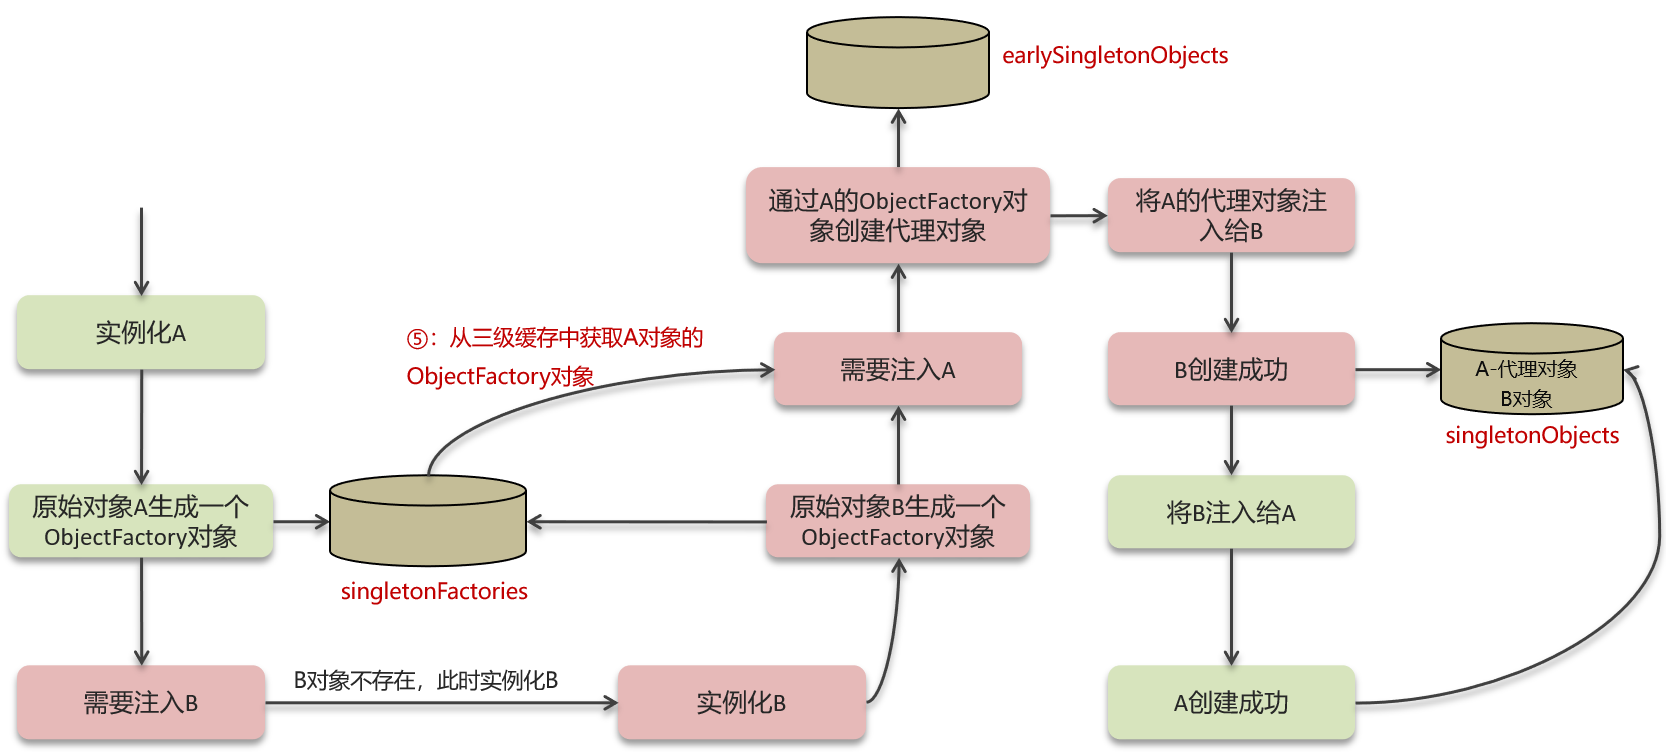

**典型A→B→A过程，前提是允许这类循环：**

1. A先完成实例化，创建提供早期引用的工厂；此时属性未填完。
2. 填A的b属性，发现B不存在，开始创建B。
3. B实例化并准备其早期引用，填a属性时再次请求A。
4. 容器发现A正在创建，按条件从二级获取，或调用三级工厂取得A的早期引用，并放到二级。
5. B获得A的早期引用，完成其初始化与单例注册。
6. A获得B，完成初始化；将最终一致的引用注册到一级，清理相应早期条目。

**AOP为什么相关：** 依赖方应拿到与最终暴露对象一致的引用。早期工厂可以经`getEarlyBeanReference`等扩展点提前取得适当代理，避免B拿原对象、其他调用拿代理而行为不一致；不是每个早期引用都一定是代理。

**修正“三级缓存创建某个对象”：** 此处工厂主要负责按需取得已实例化单例的早期引用/代理，不是重新new一个A。ObjectFactory与用户可定义的FactoryBean也不是同一个概念。

两级结构可以在一些无代理或采用其他设计的场景处理循环；三级是Spring将“工厂延迟提供早期引用”与“已取早期引用”分开的设计，不能说数学上不存在任何两级解决办法。

早期对象可能还没完成初始化，不要在B初始化中立刻调用A依赖完整状态的方法。能启动也不代表依赖结构合理，优先减少双向职责。


## 13. 构造器循环、@Lazy与允许循环的边界

**课件第27～29页：** A构造函数需要B，B构造函数又需要A，会在双方尚未实例化时卡住；给某一注入点使用@Lazy是课堂解决示例。

~~~java
@Component
public class A {
    private final B b;
    public A(@Lazy B b) {
        this.b = b; // 先接收延迟解析代理
        // 不要在这里立即调用b去触发另一侧构造
    }
}
~~~

**为什么普通三级缓存不能直接解构造环？** 需要先有原始A，才能提供其早期引用；若构造A必须先完整创建B，而B构造又需要A，尚无可暴露的A。属性注入与构造注入的时机不同。

**@Lazy注入点的补充原理：** 可先注入延迟解析代理，在实际使用时才请求目标Bean；不是把构造器参数先设成null，也不意味着整个程序里只要有一个@Lazy就能处理所有环。构造/初始化期间马上调用它，仍可能触发同一问题。

| 场景 | 结论与条件 |
|---|---|
| 单例属性/setter形成环 | 框架与配置允许、提前引用兼容时可能处理 |
| 双方构造器直接形成环 | 通常无法依靠已有对象提前暴露解决 |
| prototype形成创建环 | 通常没有上述单例缓存机制来解决 |
| 某些包装/代理不兼容早期引用 | 可能仍失败或发生引用一致性问题 |
| 延迟代理/ObjectProvider按需获取 | 有机会延后目标创建，调用时机仍需正确 |

**版本修正：** Spring Framework对一些单例循环有处理能力，但Spring Boot **2.6起默认禁止循环依赖**。课件“Spring允许大部分循环”不能直接当成Boot当前默认行为。`spring.main.allow-circular-references`是相关配置项，具体以版本为准，本篇没有修改它。

优先方案是重新分配职责、抽出公共协作服务或通过明确事件/回调减少双向依赖。开启开关只能允许部分机制尝试，不能解决所有构造器环，也不能修复设计耦合。

**面试回答：** 先判断作用域、注入时机、提前引用条件和Boot开关，再讲三级缓存过程。@Lazy是延迟解析手段，其成立依赖于真正推迟调用。


## 14. Spring MVC视图模式执行流程

**课件第30～31、33页：** 请求通过DispatcherServlet，查处理器，适配调用Controller，取得ModelAndView，解析视图并渲染。

| 组件 | 职责 |
|---|---|
| DispatcherServlet | 前端控制器，协调各处理阶段 |
| HandlerMapping | 根据请求找到Handler及拦截器链等 |
| HandlerExecutionChain | 处理器与相关拦截器的组合 |
| HandlerAdapter | 判断并适配处理器调用，组织参数与返回值处理 |
| Controller/Handler | 执行业务入口，调用Service |
| ViewResolver | 将逻辑视图名称等解析为View |
| View | 使用模型渲染响应，例如页面 |

~~~text
请求 → DispatcherServlet → HandlerMapping
     ← HandlerExecutionChain
     → HandlerAdapter → 参数解析 → Controller
     ← 返回值/模型 → ModelAndView
     → ViewResolver → View → 渲染模型 → 响应
~~~

`@Controller`方法可以返回逻辑视图名，不要求用户代码每次显式new ModelAndView；框架的返回值处理机制可能建立相应模型与视图结果。

**补充：** 参数处理包含类型转换、参数解析器、绑定与校验等，不只是“调用方法”。路由还可依据HTTP方法、参数、头、consumes/produces条件，并非简单只有`URL→类名#方法名`键值映射。

课件把视图模式称为“JSP阶段”，JSP是例子，模板还可以是其他View技术。名称`HandlerAdaptor`、`ViewReslover`等课件拼写应为`HandlerAdapter`、`ViewResolver`。

**面试简答：** Mapping负责找到谁，Adapter负责怎样调用，Resolver负责怎样获得视图，View负责怎样渲染；DispatcherServlet组织全过程。


## 15. Spring MVC接口模式与消息转换

**课件第32、34页：** `@ResponseBody`通过HttpMessageConverter将返回结果写入响应，常见为JSON，不走普通视图解析渲染。

~~~java
@RestController
@RequestMapping("/users")
public class UserController {
    private final UserService userService;
    public UserController(UserService userService) {
        this.userService = userService;
    }
    @GetMapping("/{id}")
    public UserDto find(@PathVariable("id") Long id) {
        return userService.findDto(id);
    }
}
~~~

这是学习片段，UserDto/UserService未在本篇实现。`@RestController`组合`@Controller`和`@ResponseBody`，返回对象按消息转换机制处理。

~~~text
HTTP请求 → HandlerMapping → RequestMappingHandlerAdapter
         → 参数解析（含必要的请求体转换/校验）
         → Controller方法 → 返回值处理
         → 合适的HttpMessageConverter → 响应体
~~~

**修正“ResponseBody必定转JSON”：** 它表示响应体语义，格式由返回类型、Content-Type/Accept、produces和可用转换器决定。字符串、字节、JSON等都可能；`@RequestBody`同样不只针对JSON。

| 数据来源 | 常见注解 | 示例 |
|---|---|---|
| 路径变量 | @PathVariable | `/users/1`中的1 |
| 查询参数/表单参数 | @RequestParam | `?page=2` |
| 请求体 | @RequestBody | JSON反序列化成DTO |
| 请求头 | @RequestHeader | 某Header值 |

**补充边界：** 返回DTO避免直接序列化不必要实体字段；返回MyBatis带延迟加载代理的对象可能触发额外SQL。JSON字段可见性、日期格式与循环引用也需配置，不是Controller注解自动解决。

课件“前后端分离阶段（异步请求）”通常指浏览器Ajax调用。Ajax本身不代表服务器使用Servlet异步处理，也不自动等同WebFlux；同步返回JSON接口同样可用于前后端分离。


## 16. 拦截器、过滤器与异常处理（补充）

课件HandlerExecutionChain包含处理器拦截器。本节补充其位置，便于定位Web问题。

| 能力 | 主要位置 | 适合的观察范围 |
|---|---|---|
| Servlet Filter | DispatcherServlet外的过滤器链 | Servlet请求/响应，依映射可涵盖更多路径 |
| HandlerInterceptor | 找到MVC Handler后，由MVC组织 | Handler及请求处理生命周期 |
| AOP | 代理方法执行 | 被切点命中的容器对象方法，不只限Web |

它们不能随意互换：Filter与MVC路由时机不同，AOP是否生效依赖代理入口。复杂认证授权常有专门框架，应与其现有链路一致。

**拦截器正常顺序示意：**

~~~text
preHandle：按配置顺序
  → Handler调用
postHandle：通常逆序（正常完成时）
  → 相应视图渲染/返回处理
afterCompletion：通常逆序，对已成功进入的拦截器进行清理
~~~

抛异常、preHandle返回false、异步分派时顺序存在分支；不能背一张正常图后保证每次postHandle都运行。ResponseBody返回值可能在HandlerAdapter阶段已写入响应，postHandle不总能修改响应体。

**异常解析：** HandlerExceptionResolver等组织MVC异常处理，常见`@ExceptionHandler`、`@ControllerAdvice`/`@RestControllerAdvice`。返回状态码与错误体要和业务协议一致，不能把所有错误都变成200加错误字符串。

~~~java
@RestControllerAdvice
public class ApiErrors {
    @ExceptionHandler(IllegalArgumentException.class)
    public ResponseEntity<String> invalid(IllegalArgumentException e) {
        return ResponseEntity.badRequest().body("请求参数不合法");
    }
}
~~~

教学片段只表示机制，没有覆盖认证、内部错误和项目完整错误模型。过滤器外/框架前的错误未必进入ControllerAdvice。


## 17. Spring Boot自动配置：课件2.3.9链路

**课件第35～37页：** `@SpringBootApplication`主要组合@SpringBootConfiguration、@EnableAutoConfiguration、@ComponentScan。

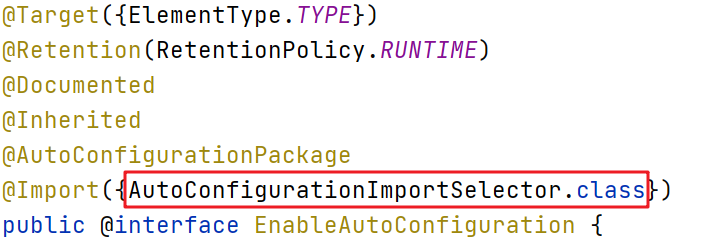

| 注解 | 作用 |
|---|---|
| @SpringBootConfiguration | 标识Boot配置类，基于@Configuration |
| @ComponentScan | 组件扫描，通常以启动类包及子包为默认范围 |
| @EnableAutoConfiguration | 开启自动配置候选导入与条件判断 |

**按课件Spring Boot 2.3.9解释：**

~~~text
@EnableAutoConfiguration
  → @Import(AutoConfigurationImportSelector.class)
  → 按机制读取classpath中的自动配置候选
  → META-INF/spring.factories
       key：org.springframework.boot.autoconfigure.EnableAutoConfiguration
       value：候选自动配置类全名列表
  → 结合排除、筛选、排序与条件判断
  → 注册满足条件的配置和Bean
~~~

Spring Boot不是遍历所有classpath类后无条件new对象；它按候选注册元数据与条件组织配置。`@ComponentScan`和自动配置导入是不同入口，依赖中的自动配置类不需要位于应用启动类包下面。

**课件Redis示例：** RedisAutoConfiguration上有`@ConditionalOnClass(RedisOperations.class)`；配置方法`redisTemplate`有`@ConditionalOnMissingBean(name="redisTemplate")`。类存在是其中一个条件，方法还有自己的条件，相关依赖也要满足。

**修正第37页“class存在就把所有Bean放进去”：** 条件可在配置类和@Bean方法上，后者可能仍不匹配。此例按**名称**判断redisTemplate缺失，不能统一说任意同类型Bean都会使该方法后退。

自动配置的便利是根据依赖、已有Bean与属性提供默认实现，并允许用户按约定定制。是否能“用户Bean覆盖默认Bean”，取决于具体缺失条件、类型/名称与处理时机，不是所有自动配置都有完全相同规则。


## 18. 自动配置版本变化与排查（补充）

课件是Boot 2.3.9，回答实际项目时必须先确定版本。

| 版本范围 | 自动配置候选的主要注册入口 |
|---|---|
| 课件Boot 2.3.9等旧式链路 | `META-INF/spring.factories`的EnableAutoConfiguration键 |
| Boot 2.7过渡 | 引入`META-INF/spring/org.springframework.boot.autoconfigure.AutoConfiguration.imports`，并兼容部分旧入口 |
| Boot 3.x | 自动配置候选使用AutoConfiguration.imports；不再以spring.factories的旧键注册自动配置 |

**边界：** spring.factories还可能用于其他扩展机制，不能说Boot 3中这个文件完全不存在或不再被任何机制使用。本节没有对最新Boot所有实现进行联网核验，实际按依赖版本检查。

| 条件 | 通常判断 |
|---|---|
| @ConditionalOnClass | 指定类是否在classpath |
| @ConditionalOnMissingBean | 指定类型/名称等Bean是否缺失 |
| @ConditionalOnBean | 是否有指定Bean |
| @ConditionalOnProperty | 属性值/存在性是否符合条件 |
| @ConditionalOnWebApplication | 是否属于相应Web应用类型 |

**排查顺序：** 确认依赖与版本 → 找对应候选入口 → 查看配置类/方法条件 → 查用户Bean与属性 → 检查排除项 → 结合条件评估报告。

`debug=true`等可用于查看条件评估信息；项目已有Actuator且相应端点允许访问时，也可查看相关诊断能力。调试范围与实际配置应明确，本篇未改开关或公开端点。

**starter与自动配置不同：** starter主要组织依赖；自动配置模块提供候选配置与条件。加入starter通常使类与配置可用，但并不保证某Bean一定创建。

Boot 3/Spring 6常涉及Java基线与javax→jakarta生态迁移。不能只替换自动配置文件名就认为项目升级完成，Servlet、持久化、注解依赖等要整体核对。

**面试简答：** Boot通过导入选择器等机制获取注册的候选自动配置，再基于类路径、属性与现有Bean判断。旧版本讲spring.factories，新版本讲imports；最终落到实际生效的Bean与条件证据。


## 19. Spring、MVC与Boot常见注解

**课件第38～41页：** 表格列出组件、注入、配置、AOP、Web映射和Boot组合注解。

| 注解 | 正确用法/作用 | 课件补充 |
|---|---|---|
| @Component | 通用组件定义 | 要被扫描或注册才成为Bean |
| @Service / @Controller / @Repository | 语义化组件标记 | Repository在适当后处理器下还能参与异常转换 |
| @Autowired | 按类型等规则解析依赖 | 可用于构造器、方法、字段，不只字段 |
| @Qualifier | 进一步限定候选 | 不只“按名称”，可表达限定语义 |
| @Primary（补充） | 多候选时优先选择 | 不是对全部集合注入都只保留一个 |
| @Scope | 指定生命周期范围 | 不等于线程安全声明 |
| @Configuration | Java配置类 | proxyBeanMethods影响内部@Bean调用 |
| @Bean | 注册方法产生的对象 | 适合第三方对象等，参数可注入依赖 |
| @ComponentScan | 指定扫描范围 | 不是自动配置的同义词 |
| @Import | 导入配置/类/选择器/注册器等 | 具体由导入对象类别决定 |
| @Aspect / @Pointcut / @Around等 | 声明切面与通知 | 仍要有AOP基础设施与正确代理调用 |

**补充注入习惯：** 只有一个构造器时，现代Spring常可省略其@Autowired；多个候选仍需清楚指定。构造注入便于表达必需依赖与测试，但构造器环不能因此自动解决。

| Web注解 | 作用 |
|---|---|
| @RequestMapping | 类/方法映射，含路径、HTTP方法与其他条件 |
| @GetMapping / @PostMapping等 | 特定HTTP方法的组合映射 |
| @RequestBody | 使用消息转换读取请求体 |
| @RequestParam | 读取请求参数，可配置必填和默认值 |
| @PathVariable | 读取路径变量；课件@PathViriable拼写错误 |
| @RequestHeader | 读取指定请求头 |
| @ResponseBody | 返回值写入响应体，格式由转换机制决定 |
| @RestController | @Controller与@ResponseBody的组合 |
| @ControllerAdvice / @ExceptionHandler（补充） | MVC全局/方法异常等处理 |

**Boot常见注解：** @SpringBootApplication及其三个核心组合；@ConfigurationProperties绑定一组属性（补充）；条件注解控制自动配置是否参与。

注解只表达元数据与约定；是否生效取决于处理器、扫描、容器与调用入口。排错时先查这些条件，不把它们当作独立执行的魔法。


## 20. MyBatis组件与SQL执行流程

**课件第42～44页：** 读取配置与Mapper → 构建SqlSessionFactory → 获取SqlSession → Executor执行 → MappedStatement提供映射信息 → 参数与结果处理。

| 组件 | 职责 | 生命周期/边界 |
|---|---|---|
| Configuration | 保存MyBatis配置与映射等 | 根据XML/注解与集成配置构建 |
| SqlSessionFactory | 创建SqlSession | 通常长期复用，一套配置可有一个；多数据源可有多个 |
| SqlSession | 查询、更新、提交等会话入口 | 原始DefaultSqlSession不应跨线程共享 |
| Mapper代理 | 将接口方法关联到映射语句 | 不等于每个方法都有手写实现类 |
| Executor | 执行查询/更新并参与缓存管理 | SIMPLE/REUSE/BATCH等方式与缓存包装有关 |
| MappedStatement | 一条映射语句的元数据 | ID、命令类型、SQL来源、映射、缓存设置等 |
| BoundSql（补充） | 本次调用解析后的SQL与参数映射 | 可因动态SQL与参数不同而变化 |
| StatementHandler等（补充） | JDBC语句准备、参数设置、结果处理 | 最终依靠JDBC驱动访问数据库 |

**补充执行链路：**

~~~text
Mapper方法调用
  → 根据namespace + 方法/语句ID定位MappedStatement
  → 动态SQL等生成本次BoundSql
  → Executor组织缓存与执行
  → StatementHandler准备JDBC Statement
  → ParameterHandler设置参数
  → JDBC执行
  → ResultSetHandler结合resultMap/resultType映射结果
  → 返回对象/集合
~~~

实际代码内部顺序可因语句、缓存命中、批处理、插件等出现分支。本图说明组件职责，不表示每次查询都一定访问数据库。

课件“会话工厂全局一个”和“每次操作一个会话”应加条件：通常每套Configuration复用工厂；一个SqlSession可以有多次操作。Spring事务中多个Mapper操作可复用同一个事务关联会话，不是每条SQL都必然创建独立会话。

**面试回答：** 从配置构建、Mapper代理、MappedStatement、执行器到参数与结果处理；再说明缓存命中会改变数据库访问次数。


## 21. MappedStatement、参数绑定与结果映射

**课件第43页：** 调试截图展示`com.itheima.mapper.UserMapper.selectById`、SELECT命令、参数映射与`select * from tb_user where id = ?`。

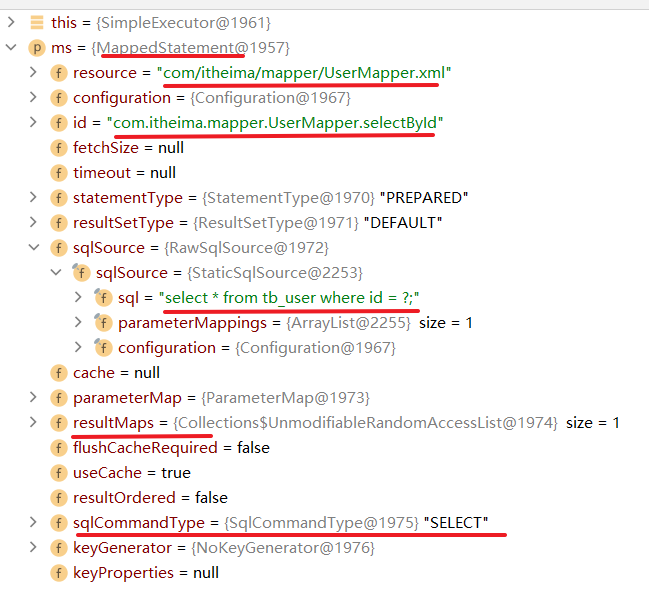

MappedStatement是映射语句元信息，不是本次查询返回结果，也不是把运行参数直接拼进原始字符串后的唯一对象。

~~~xml
<!-- 学习片段，未执行；User类型需要正确的别名或全名配置 -->
<select id="selectById" resultType="User">
    SELECT id, username FROM tb_user WHERE id = #{id}
</select>
~~~

| 写法 | 机制 | 适用边界 |
|---|---|---|
| `#{id}` | 通常生成`?`，通过PreparedStatement参数绑定 | 用于值参数；类型处理还需正确 |
| `${column}` | 将文本替换进SQL结构 | 外部可控时有注入风险；结构参数应由受控白名单选择 |

不能用`#{}`绑定表名或列名来代替SQL结构。排序字段、表名等若需动态选择，应在业务允许列表里选择固定SQL片段；不直接拼接任意用户输入。

**多参数补充：** 使用明确`@Param`命名或对象参数，避免过度依赖编译参数名与版本默认映射。动态SQL的if/where/foreach等改变最终SQL与参数映射，也会影响缓存键和执行计划。

**结果映射：** resultType适合较简单映射；resultMap可显式定义列与属性、id、association和collection。字段命名不一致可用别名或映射，驼峰转换等要按配置；“返回User”不表示所有字段必被自动正确赋值。

**TypeHandler（补充）：** 处理Java/JDBC类型之间的转换。时间、枚举、JSON或自定义类型需要确认处理方式，不能只看字段名称。

**与数据库篇关联：** 绑定参数类型要与列类型匹配，否则可能影响索引定位。PreparedStatement绑定减少SQL值拼接风险，但不能修复所有SQL逻辑或权限问题。


## 22. MyBatis与Spring集成的会话范围（补充）

课件采用`sqlSessionFactory.openSession()`演示会话。实际Spring项目经常使用MyBatis-Spring集成，不能把手动代码的每一步直接套到所有Mapper调用。

| 使用方式 | 会话管理 | 线程边界 |
|---|---|---|
| 手动DefaultSqlSession | 调用方负责正确提交/回滚/关闭 | 不应让多个线程共享同一会话 |
| Spring中的SqlSessionTemplate | 在框架事务与资源规则下取得/复用会话并组织清理 | Template通常可被单例共享，但底层会话不因此变成可任意共享 |
| Spring注入Mapper代理 | 方法经集成层使用相应会话 | 同一事务范围是否复用取决于集成配置与线程/资源 |

同一Spring事务里重复同一查询，在满足一级缓存条件时可能不再访问数据库；事务外两个Mapper调用可能采用不同底层会话，不能因Mapper Bean是单例就断言命中同一一级缓存。

**手动管理示意，未运行：**

~~~java
try (SqlSession session = factory.openSession()) {
    try {
        UserMapper mapper = session.getMapper(UserMapper.class);
        // 执行业务操作
        session.commit();
    } catch (RuntimeException | Error e) {
        session.rollback();
        throw e;
    }
}
~~~

受检异常和具体业务错误路径也要完整处理；该片段仅展示资源/事务责任，不包含业务实现。在Spring管理事务中，不应照搬手动commit/rollback以绕开框架。

**集成排错：** 数据源是否一致、事务管理器是否管理该资源、Mapper是否正确扫描、线程是否改变、是否手动打开额外会话。出现“事务回滚但部分SQL保留”时，这些比只检查注解更重要。

SqlSessionFactory通常可长期共享，但一套应用不必只有一个；MyBatis自身也不是数据库连接池，实际连接来源由DataSource等配置决定。


## 23. MyBatis延迟加载：使用与映射

**课件第45～47页：** 用户与订单是一对多关系。查用户时同时查订单是立即加载；需要订单时再查是延迟加载。MyBatis支持association和collection的关联延迟加载。

**常见3.x配置示例，未运行：**

~~~xml
<settings>
    <setting name="lazyLoadingEnabled" value="true"/>
    <setting name="aggressiveLazyLoading" value="false"/>
</settings>
~~~

`lazyLoadingEnabled`常见默认false。单个关联的`fetchType="lazy"`或`eager`等可覆盖相关全局设置；默认值与精确行为应对照项目版本。

~~~xml
<!-- 示例：按需执行嵌套查询，类型别名需自行正确配置 -->
<resultMap id="userWithOrders" type="User">
    <id column="id" property="id"/>
    <result column="username" property="username"/>
    <collection property="orderList"
                column="id"
                ofType="Order"
                select="selectOrdersByUserId"
                fetchType="lazy"/>
</resultMap>

<select id="selectUser" resultMap="userWithOrders">
    SELECT id, username FROM tb_user WHERE id = #{id}
</select>
<select id="selectOrdersByUserId" resultType="Order">
    SELECT id, user_id, name FROM tb_order WHERE user_id = #{id}
</select>
~~~

这是一份补充教学映射，表/字段与配套代码未核对，不能称为课件项目原文件。需根据单参数映射与实际类型调整。

**机制前提：** 这种关联是可按需触发的嵌套select。把所有关联字段通过一次JOIN已经查出并嵌套映射，与“稍后额外查询”是不同方式；开启开关不会自动把任何JOIN拆成懒查询。

**收益与代价：** 不使用关联时可省SQL；大量逐条访问关联可能出现N+1。例如查100个用户，再访问每人的订单，可能增加许多查询，需按访问场景考虑批量查询或受控JOIN等。


## 24. 延迟加载代理、触发条件与失败边界

**课件第46～47页：** 用代理拦截getter，加载订单后填入属性并返回。课件写“CGLIB、判断属性null”，是简化描述。

**修正代理实现：** 现代MyBatis 3.x常见默认代理工厂是Javassist；CGLIB是历史可选实现，在较新版本已被弃用等。具体按版本与`proxyFactory`配置，不能回答MyBatis延迟加载必然只用CGLIB。

**补充正确流程：**

~~~text
映射主对象时，为尚未加载的关联登记加载任务
  → 返回相应代理对象
  → getter或配置的触发方法被调用
  → 根据未执行的加载任务与策略加载关联
  → 使用Executor/SQL查询并映射结果
  → 填充属性，移除/更新对应待加载状态
  → 返回属性结果
~~~

属性值为null不充分表示“尚未加载”：查询已执行但没有关联行，也可能得到null或空结果。框架依据登记的加载器/状态判断，不是每次见null都无限重查。

| 常见触发点 | 为什么要关注 |
|---|---|
| getter | 读取关联时触发相应任务 |
| toString / equals / hashCode等 | 受lazyLoadTriggerMethods等配置影响，日志/调试可能触发 |
| aggressiveLazyLoading | 开启时方法调用可能触发更广泛加载，旧版本默认值有差别 |
| JSON序列化 | 遍历getter可能执行数据库查询，响应阶段突然产生N+1 |

**会话与事务：** 原会话关闭后，一些实现/配置会尝试另开执行资源，可能在原事务外读取，也可能因环境不可用而失败。不能统一说“会话关闭后一定能加载”或“一定失败”；更不能假定仍共享原事务快照。

**工程建议：** Service内明确需要的数据并转换为DTO，控制返回范围和数据库访问时机；不要让日志、调试或JSON过程承担隐含查询。跨线程传递代理也不等于可以安全共享原SqlSession。

**面试简答：** 延迟加载用代理与已登记的关联加载任务，调用触发点时查询并填充属性；要说明代理实现版本、触发策略、N+1和会话/事务边界。


## 25. MyBatis一级缓存

**课件第48～49、52页：** 一级缓存是SqlSession范围的本地缓存，底层基础实现可使用PerpetualCache与HashMap，默认常见作用范围是SESSION。

~~~java
// 学习片段，未运行；假定同一会话、同一映射、参数与配置
try (SqlSession session = factory.openSession()) {
    UserMapper m1 = session.getMapper(UserMapper.class);
    UserMapper m2 = session.getMapper(UserMapper.class);
    User u1 = m1.selectById(6);
    User u2 = m2.selectById(6);
}
~~~

在缓存规则满足且中间没有清理/更新等操作时，两次查询通常只访问数据库一次。两个Mapper引用并不自动表示两个会话；相反，两个不同SqlSession一般不共享一级缓存。

**补充缓存键：** 通常包含MappedStatement ID、分页参数、最终SQL、绑定参数、环境等信息。不是只用`id=6`，也不是只要SQL文本相同就保证共享。

| 事件/配置 | 常见影响 |
|---|---|
| 同会话执行更新/插入/删除 | 默认会清理相应本地缓存，不仅限当前Mapper |
| commit / rollback / close | 清理会话本地缓存等；细节按执行器与调用看 |
| clearCache() | 显式清理本地缓存 |
| select配置flushCache=true | 可要求查询前清缓存 |
| localCacheScope=STATEMENT | 将本地缓存保留范围限制到语句级，不按跨语句SESSION复用 |

**对象引用风险：** SESSION缓存可能让后续查询获得同一个对象引用。修改u1字段，u2可能观察到内存修改，但不表示数据库已更新。不要把“查询获得对象后改字段”误当成MyBatis自动脏检查持久化。

一级缓存可能返回旧值，另一会话/外部系统更新不自动让本会话知道。结合数据库隔离级别与业务需求，不要把一级缓存当作全局一致性保证。

**Spring集成补充：** 同一事务可能复用会话；事务外连续调用未必共享同一底层会话，所以看到两次SQL不一定表示MyBatis配置失效。


## 26. 二级缓存、启用条件与一致性

**课件第50～52页：** 二级缓存通常按Mapper namespace组织，可跨SqlSession。需要全局允许与命名空间缓存定义；课件XML片段引号/闭合不完整，以下已修正。

~~~xml
<!-- mybatis-config.xml中的片段，未执行 -->
<settings>
    <setting name="cacheEnabled" value="true"/>
</settings>

<!-- 某个Mapper XML内 -->
<mapper namespace="com.example.mapper.UserMapper">
    <cache/>
    <!-- 其他映射语句 -->
</mapper>
~~~

**重要修正：** 常见MyBatis 3.x中全局`cacheEnabled`默认true，但默认没有为每个namespace自动建立二级缓存，未声明`<cache/>`/相关注解等时没有该namespace的缓存。因此“二级缓存默认关闭”适合描述一般默认效果，不能说全局参数默认false。

| 条件 | 对二级缓存的影响 |
|---|---|
| namespace有cache或合适cache-ref等 | 决定采用哪个缓存范围 |
| 全局cacheEnabled允许 | 允许相应缓存机制工作 |
| 查询useCache=true等 | 决定该语句是否参与二级缓存 |
| 提交/正常结束相应事务性缓存阶段 | 待缓存结果才按规则对后续会话发布 |
| rollback或需要回滚的关闭 | 不应将未确认的待缓存结果当成已提交发布 |
| 默认DML flushCache | 清理相应namespace缓存的失效过程，与事务性缓存规则结合 |

**修正“一级数据提交/关闭全部搬到二级”：** 二级缓存通过CachingExecutor与事务性缓存管理等登记/提交候选结果，不是把一级HashMap的全部内容简单搬过去。关闭是否提交候选，要看是否回滚、会话是否有未提交修改等，不能只要close就保证发布。

课件第50页未开启时显示两次SQL；正确开启并正常完成第一会话后，第二会话同键查询有机会命中。第一次尚未发布、键变化、更新失效或配置不匹配时，仍会执行SQL。本篇未运行，不提供虚构日志。

**Serializable条件：** 默认`<cache/>`常使用读写缓存的序列化复制，结果对象及其对象图需要支持相应序列化。`readOnly=true`等模式或自定义缓存实现有不同要求，不能说任何二级缓存都绝对要求Serializable；只读模式共享引用时更应避免修改结果对象。

**一致性边界：**

- namespace不是数据库表级的自动依赖分析。另一Mapper更新同一张表，默认未必使当前namespace的查询缓存失效；cache-ref等共享也需明确设计。
- 外部程序改库不会自动失效MyBatis缓存，关联多表查询的变更更难保证完整失效。
- 默认本地缓存不能视为多应用实例共享的Redis式全局缓存，自定义实现另论。
- 事务与缓存失效顺序、并发、跨实例会影响读到的数据，不宜用一条开启配置保证强一致。

**面试简答：** 一级按会话，二级按namespace，可跨会话但需配置与事务性发布；重点说明键、失效范围、对象复制以及跨Mapper/外部写入的陈旧风险。


## 27. 高频面试自测与回答骨架

先讲主干，追问再解释条件。以下是知识提纲，不是可以冒充实际经历的项目答案。

| 问题 | 回答主干 | 必须能解释的追问 |
|---|---|---|
| Spring Bean都是单例吗？ | 默认singleton，可指定其他作用域 | 每容器每定义，不是整个JVM每类一个 |
| 单例线程安全吗？ | 容器不自动保证业务线程安全，分析共享状态与依赖 | count++、volatile、prototype注入单例 |
| AOP是什么？ | 将公共横切逻辑通过切点和通知复用 | 连接点、环绕proceed、返回与异常 |
| 用AOP做过什么？ | 按真实场景说明匹配方法、采集、保存与失败策略 | 不伪造项目；日志不能吞异常或泄露任意参数 |
| Spring事务怎么实现？ | 代理通知解析属性，事务管理器获取/参与事务，提交/回滚 | Spring与数据库职责，线程/资源边界 |
| 事务不回滚有哪些情况？ | 代理入口、回滚规则、异常传播、资源范围逐层排查 | 自调用、受检异常、rollback-only、版本可见性 |
| Bean生命周期？ | 定义→实例化→注入→初始化回调/后处理→暴露→销毁 | PostConstruct、代理、prototype销毁 |
| 三级缓存是什么？ | 完成单例、已取早期引用、早期引用工厂 | 早期代理一致性与未初始化风险 |
| 构造器循环能解决吗？ | 无原始实例时不能普通提前暴露；设计或延迟解析 | @Lazy真实代理、不能提前调用，Boot开关 |
| MVC执行流程？ | Mapping找Handler，Adapter调用，返回值处理 | 视图模式与ResponseBody不同分支 |
| Boot自动配置原理？ | 导入注册候选，按类/属性/Bean条件决定 | 2.3.9 factories与新imports、方法级条件 |
| MyBatis执行流程？ | Mapper→MappedStatement→Executor→JDBC→映射 | BoundSql、参数绑定、会话生命周期 |
| 支持延迟加载吗？ | 可按需加载关联，通过代理与加载任务 | 默认、fetchType、Javassist、N+1、触发方法 |
| 一二级缓存区别？ | 一级会话，二级namespace且需配置/发布 | 键、提交/回滚、跨Mapper与外部写入 |

**AOP回答示例：**

> AOP把多个业务方法共有的逻辑抽成切面。我们在____学习/工作场景中用____切点匹配____方法，通过环绕通知调用proceed，采集____并保留原返回值与异常。日志保存失败采用____策略。Spring代理模式下，调用必须经过代理，自身内部调用不自动进入增强。

**生命周期回答示例：**

> 容器先注册BeanDefinition，再产生实例并解析/注入依赖，执行相关Aware、初始化前后处理与初始化回调，最后暴露可用引用，可能是代理。容器关闭时按作用域处理销毁；prototype一般不由容器自动跟踪销毁。循环依赖与实例化时机、提前引用和代理一致性有关。

**自动配置回答示例：**

> 先确定Boot版本。启动类的SpringBootApplication开启自动配置，相关导入机制读取注册的候选配置，结合条件与排除规则决定哪些参与。课件2.3.9主要用spring.factories的EnableAutoConfiguration键；Boot 3自动配置候选用imports文件。候选不等于所有Bean都生效，还要看类级和方法级条件。

**缓存回答示例：**

> MyBatis一级缓存通常按SqlSession，二级按namespace并可跨会话。二级需要配置和相应事务性发布，不是同一id查询就一定命中。更新默认触发所属范围的失效，但跨Mapper、外部程序和多实例不一定自动一致。是否在项目启用，应由访问与新鲜度要求决定。


## 28. 学习练习与验证方案（尚未执行）

以下用于自行在明确的测试项目中验证；本篇没有编译代码、启动应用或执行数据库实验，不把预期写成实测结果。

### A. 单例与共享状态

在测试Bean中观察对象实例数量与共享count。对比局部变量、AtomicInteger与复合计数逻辑，分别说明它们解决什么。并发实验要记录请求数、实例数和实际值，不用“线程安全”标签代替证据。

### B. AOP与事务入口

对比外部代理调用、内部this调用、手动new对象。记录通知是否进入、返回值与异常是否保留，以及数据库最终状态。事务实验至少包括：运行时异常、受检异常、catch后返回、rollbackFor、共享事务rollback-only。

**版本记录：** Spring版本、代理类型、方法可见性、事务管理器、数据源与引擎。非public实验不能只跑一个旧版本就概括Spring 6。

### C. 生命周期顺序

建立带构造器、依赖、Aware、PostConstruct、InitializingBean、initMethod和销毁回调的测试Bean；记录实际顺序，再核对后处理器与作用域。正常关闭容器和强制结束进程的行为分别理解，不伪造“所有情况都会销毁”。

### D. 循环依赖

比较单例属性环、直接构造器环、注入点Lazy以及提前调用Lazy的情况。先明确Boot版本与allow-circular-references设置；如果启动失败，记录异常和阶段，再解释为什么缓存没有可暴露实例。

### E. MVC与自动配置

返回一个逻辑视图与一个DTO，观察处理分支；按正确媒体类型发送请求，检查参数解析、响应Content-Type与错误码。查看自己版本的自动配置候选文件和条件报告，验证提供自定义Bean后具体哪条条件变化。

### F. 延迟加载

分别只取用户、访问orderList、打印toString、序列化DTO/实体，观察SQL数量。比较fetchType、aggressiveLazyLoading与触发方法配置，确定原会话是否仍可用、查询是否在原事务内。

### G. 一级与二级缓存

| 实验 | 应关注的变量 |
|---|---|
| 同SqlSession两次同键读 | 键、localCacheScope、是否中间清理 |
| 不同SqlSession读 | 是否有二级cache、第一会话是否已正常发布 |
| 同会话读后更新再读 | 默认失效与事务状态 |
| 第一会话rollback再开第二会话 | 候选结果是否被丢弃，不只看close调用 |
| Mapper A查询、Mapper B改同表 | namespace是否共享，陈旧风险 |
| 外部连接修改再读 | 数据库隔离与MyBatis缓存各自的影响 |

记录实际SQL次数、对象引用是否相同、事务提交点与结果；不能只凭Java对象打印两次判断数据库执行了两次。

所有实验保持“版本、设置、步骤、预期、实际、差异原因、未解决问题”记录。当前状态统一为尚未执行。


## 29. 课件修正与版本提醒

以下是整理者补充，正文已解释原因。课件是面试入门材料，部分句子不能脱离条件背诵。

| 课件简化/不完整处 | 建议表达 |
|---|---|
| 单例Bean不是线程安全/无状态就是线程安全 | singleton不提供业务并发保证；是否安全看共享可变状态与依赖 |
| 改prototype即可解决状态问题 | 单例注入prototype可能只获取一次，仍需正确生命周期/获取方式 |
| 每请求必然分配一个新线程 | 常规Servlet请求通常由线程池等处理，异步/响应式有不同模型 |
| 日志Around最后return null | 必须按业务意图调用proceed并保留返回与异常 |
| 事务等于手写开启、执行、提交三步 | 还包含传播、属性、资源参与、回滚标记与清理 |
| 默认只回滚非检查异常 | 常见默认RuntimeException和Error；规则可配置 |
| catch必然导致提交 | 还需看是否已标记rollback-only、独立事务和失败路径 |
| 所有非public方法事务必失效 | 看Spring版本和代理；Spring 6类代理可支持部分非public方法 |
| rollbackFor可以修复所有事务问题 | 只影响异常匹配，无法修复绕过代理、错资源或线程切换 |
| 生命周期只按固定八步无例外 | 普通主干如此，后处理器、构造注入、早期代理等可增加分支 |
| BeanDefinition只来自XML | 也来自扫描、Java配置、导入与自动配置等 |
| 三级工厂重新创建A | 此处提供已实例化A的早期引用，可能包装代理 |
| Spring/Boot默认允许大部分循环 | 看Framework能力与Boot配置；Boot 2.6起默认禁止循环 |
| Lazy就是使用时才new原对象 | 注入点可先提供延迟解析代理，提前触发仍可能失败 |
| ResponseBody/RequestBody只能JSON | 使用消息转换器与媒体类型，不只JSON |
| 前后端分离就是服务器异步 | 浏览器Ajax与Servlet异步/WebFlux不同 |
| 自动配置始终从spring.factories读 | 课件2.3.9如此，新Boot主要使用AutoConfiguration.imports |
| class存在就加载配置所有Bean | 还看其他类级/方法级条件、排除与已有Bean |
| Qualifier只按名字，Autowired只在字段 | Qualifier是候选限定；Autowired也可用于构造器/方法等 |
| PathViriable / ViewReslover | 正确拼写PathVariable / ViewResolver |
| SqlSessionFactory全应用永远一个 | 通常每套配置长期复用，多数据源可有多个 |
| 每次操作都独立一个SqlSession | 一个会话可以多次操作，Spring事务内可复用 |
| MyBatis懒加载必用CGLIB | 现代3.x常见Javassist默认，CGLIB历史选项需按版本看 |
| 发现关联属性null就查询 | 基于未执行加载任务与策略，null也可能是已加载结果 |
| 二级缓存全局默认参数false | 常见cacheEnabled默认true，但namespace未定义cache则无二级缓存 |
| 任意close就把一级全部搬到二级 | 通过事务性缓存登记/发布，回滚或未提交关闭存在分支 |
| 二级缓存所有实现要求Serializable | 默认读写序列化模式有要求，readOnly/自定义实现不同 |
| 更新后所有查同表的Mapper都失效 | namespace范围不是自动表依赖分析，跨Mapper/外部写入需额外设计 |

**回答前先确定：** Spring/Boot/MyBatis版本、代理模式、调用入口、Bean作用域、会话与事务范围。把这些前提说清，比绝对化的“肯定生效/肯定失效”准确。

所有新增示例与版本修正均为知识整理，没有逐项联网核验最新发布版本或运行课程代码；实际项目仍以具体依赖、配置和验证结果为依据。


## 30. 来源、覆盖范围与后续学习

### 已读主课件

`04-框架篇/PPT/04-框架篇.pptx`，53页。已读取全部文字、组合形状、表格和备注；20张去重嵌入图片按总览检查，关键问答、循环依赖图、自动配置与MappedStatement截图单独查看。三张原课件图片内嵌在Notebook，打开笔记无需外部图片目录。

| 课件页 | 主题 | 本篇位置 |
|---|---|---|
| 1～2 | 框架篇与路线 | 导言、1 |
| 3～5 | 作用域、单例线程安全 | 2～3 |
| 6～11 | AOP、日志、事务原理 | 4～8 |
| 12～16 | 事务失效场景 | 8～9 |
| 17～20 | BeanDefinition与生命周期 | 10～11 |
| 21～29 | 循环依赖、三级缓存、Lazy | 12～13 |
| 30～34 | MVC视图/接口流程 | 14～16 |
| 35～37 | Boot自动配置 | 17～18 |
| 38～41 | 常见注解 | 19 |
| 42～44 | MyBatis执行流程 | 20～22 |
| 45～47 | 延迟加载 | 23～24 |
| 48～52 | 一级、二级缓存 | 25～26 |
| 53 | 空白 | 未作为正文展开 |

### 配套视频，只核对文件标题

| 序号 | 视频主题 | 笔记位置 |
|---|---|---|
| 01 | 框架篇课程介绍 | 导言、1 |
| 02 | 单例Bean线程安全 | 2～3 |
| 03 | AOP相关面试题 | 4～8 |
| 04 | 事务失效 | 8～9 |
| 05 | Bean生命周期 | 10～11 |
| 06 | 循环依赖/循环引用 | 12～13 |
| 07 | Spring MVC执行流程 | 14～16 |
| 08 | Boot自动配置 | 17～18 |
| 09 | Spring/MVC/Boot注解 | 19 |
| 10 | MyBatis执行流程 | 20～22 |
| 11 | MyBatis延迟加载 | 23～24 |
| 12 | MyBatis一级、二级缓存 | 25～26 |

12节视频未观看或转写，上表是标题与课件主题对应，不表示已读取视频口头内容。

### 未读资料与来源入口

配套代码目录列出`mybatis-demo.zip`（45KB）、`spring-demo.zip`（16KB）、`ssm-demo.zip`（48KB）。尝试下载MyBatis包时，网盘最后提示“验证码已过期”，未取得代码包；三包正文均未读取。笔记中的Java/XML示例来自课件或标记为整理者改写，不能说是代码包完整复现。

- [用户分享的Java面试资料](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)：主课件来源。
- [在线讲义入口](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)：61B文本只有这一行URL。专题目录可见，但点击“SSM框架”未进入正文，在线框架讲义正文未读取。

未编译示例、执行SQL、启动课程工程、进行并发或事务实验，未安装新框架或修改配置。事务传播、代理入口、现代版本边界、MVC扩展和实验方案等补充均在正文标识。

**学习完成标准：** 能按调用入口判断代理是否生效，按生命周期判断依赖何时可用，按版本和条件解释自动配置，按会话/namespace与事务状态解释MyBatis查询次数和陈旧风险。

下一篇对应 **05-微服务篇**，按实际课件继续整理。
